# Day 16 — Crop Yield Prediction: US Maize, 2000–2025

**Question:** can US maize yield be estimated from historical harvest,
temperature and rainfall — and how well does the model do on years it has
never seen?

**Sources:** yield — FAO via Our World in Data (`maize-yields.csv`, USA,
2000–2025, 26 rows, t/ha). Weather — Open-Meteo ERA5 archive, daily
temperature + precipitation for the Iowa and Illinois centroids, averaged
as a Corn Belt proxy for the national yield series. **Limitations up front:**
national yield vs 2-state weather proxy; only 26 annual rows; drivers are
associations, not causes; no USDA state data (the Quick Stats API needs a
key — HTTP 401 without one), so FAO/OWID is used instead.


In [1]:
from pathlib import Path
import sys

def _find_root(marker="data/processed/yield_weather.csv"):
    here = Path.cwd()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise FileNotFoundError(f"could not find {marker} above {here}")

ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
import numpy as np
print("project root:", ROOT)

project root: /home/hatch/workspace/goals/60-day-data-ai-portfolio/day-16-crop-yield-prediction


## 1. The joined dataset — 26 years, 7 features

Growing season = April–September. Features: `year` (technology trend),
`gs_temp_mean`, `gs_precip_total`, `jul_temp_mean`, `jul_precip_total`,
`jun_precip_total`, `heat_days_gs` (Apr–Sep days with daily max > 30 °C).
Split: train 2000–2019 (20), held-out 2020–2025 (6).

In [2]:
df = pd.read_csv(ROOT / "data/processed/yield_weather.csv")
df.head(8)
print(df.shape)
print(df["split"].value_counts().to_dict())
print(df.describe().T[["mean", "min", "max"]].round(2))

(26, 10)
{'train': 20, 'heldout': 6}
                      mean      min      max
year               2012.50  2000.00  2025.00
yield_t_per_ha       10.02     7.73    11.71
yield_bu_per_acre   159.68   123.09   186.48
gs_temp_mean         19.31    17.84    20.76
gs_precip_total     595.72   401.85   894.85
jul_temp_mean        23.86    20.53    28.01
jul_precip_total     91.70    21.75   203.30
jun_precip_total    117.44    35.65   227.30
heat_days_gs         26.88     4.50    55.00


## 2. Yield history — the trend dominates

Yield rose from 8.59 t/ha (2000) to 11.71 t/ha (2025), with the 2012 drought
dip (7.73 t/ha) as the lowest point in the series. The 2012 growing season
was far drier in Iowa (423.6 mm vs 1041.9 mm in 2010) with 51 heat days.

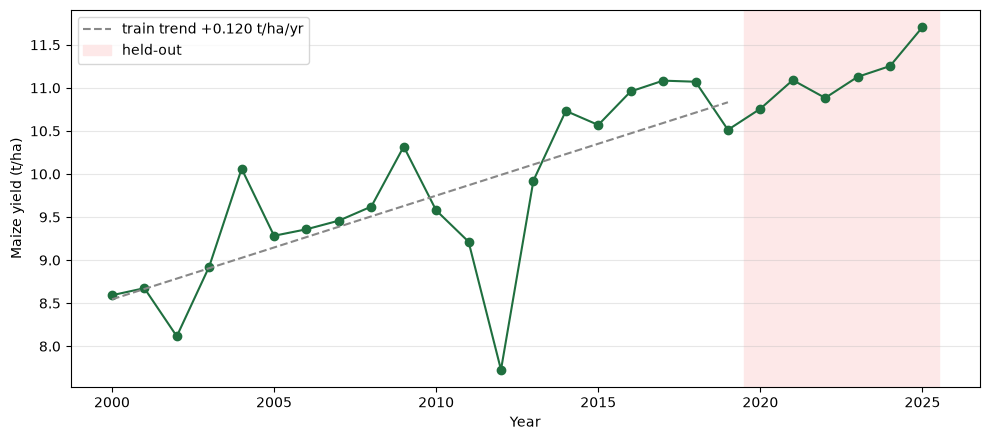

train trend: +0.1204 t/ha per year; 2012 yield: 7.73 t/ha


In [3]:
import matplotlib.pyplot as plt
train = df[df["split"] == "train"]
slope, intercept = np.polyfit(train["year"], train["yield_t_per_ha"], 1)
plt.figure(figsize=(10, 4.5))
plt.plot(df["year"], df["yield_t_per_ha"], "o-", color="#1f6f3f")
plt.plot(train["year"], slope * train["year"] + intercept, "--", color="#888888",
         label=f"train trend +{slope:.3f} t/ha/yr")
plt.axvspan(2019.5, 2025.5, color="#fde8e8", label="held-out")
plt.ylabel("Maize yield (t/ha)"); plt.xlabel("Year"); plt.legend(); plt.grid(axis="y", alpha=0.3)
plt.tight_layout(); plt.show()
print(f"train trend: +{slope:.4f} t/ha per year; 2012 yield: {df.loc[df['year']==2012, 'yield_t_per_ha'].iloc[0]:.2f} t/ha")

## 3. Models — OLS, Ridge, Random Forest vs two naive baselines

All models fit on 2000–2019 only. Baselines: `naive_last` (this year's yield
= last year's actual yield) and `naive_mean` (train-period mean).

In [4]:
import model as md
results, predictions, drivers, winner = md.run()
print(f"winner (lowest held-out RMSE): {winner}")
results[["model", "heldout_rmse_t_per_ha", "heldout_mae_t_per_ha", "heldout_r2", "heldout_bias_t_per_ha"]]

winner (lowest held-out RMSE): Ridge


,model,heldout_rmse_t_per_ha,heldout_mae_t_per_ha,heldout_r2,heldout_bias_t_per_ha
0,OLS,0.784997,0.694251,-5.756811,0.694251
1,Ridge,0.540228,0.441172,-2.200077,0.441172
2,RandomForest,0.591821,0.491884,-2.840492,-0.491884
3,naive_last,0.286745,0.267787,0.098434,-0.198748
4,naive_mean,1.478680,1.447513,-22.974742,-1.447513


## 4. The honest headline

The naive one-step persistence baseline (`naive_last`, RMSE 0.287 t/ha)
**beats every model** on the held-out years — the best model, Ridge, scores
0.540 t/ha. Yields rose smoothly through 2020–2025, so "last year's yield"
is a hard baseline to beat, and the linear models systematically
over-predict (positive bias) while the Random Forest cannot extrapolate the
trend at all (its predictions sit flat near 10.6 t/ha). All models beat the
train-mean baseline (RMSE 1.479 t/ha). Held-out R² is negative for every
model because the six held-out yields sit in a narrow band (10.76–11.71
t/ha) while the errors are ~0.5 t/ha — R² on 6 points is reported as a
secondary metric only; RMSE/MAE are the primary ones.

In [5]:
predictions.round(3)

,year,actual_t_per_ha,actual_bu_per_acre,OLS,Ridge,RandomForest,naive_last,naive_mean
0,2020,10.757,171.385,11.097,10.933,10.613,10.513,9.689
1,2021,11.090,176.685,11.454,11.262,10.765,10.757,9.689
2,2022,10.883,173.385,11.353,11.212,10.677,11.090,9.689
3,2023,11.128,177.285,12.168,11.857,10.590,10.883,9.689
4,2024,11.253,179.284,12.577,12.249,10.642,11.128,9.689
5,2025,11.705,186.484,12.333,11.952,10.579,11.253,9.689


## 5. Driver analysis — association, not causation

Pearson r with yield (26 years), standardised OLS coefficients (train fit),
and Random Forest permutation importance on the held-out years.

In [6]:
drivers.sort_values("ols_std_coef").round(3)

,feature,pearson_r,ols_std_coef,rf_perm_importance
6,heat_days_gs,-0.165,-0.489,-0.018
3,jul_temp_mean,-0.391,-0.372,0.001
2,gs_precip_total,0.031,-0.270,-0.001
5,jun_precip_total,0.228,-0.060,-0.001
4,jul_precip_total,0.230,0.109,-0.001
1,gs_temp_mean,-0.051,0.170,0.007
0,year,0.831,0.871,-0.000


The `year` trend dominates (r = +0.83) — technology and practice improve
yields over time. Among weather variables, heat hurts: `heat_days_gs`
(standardised coefficient −0.49) and July mean temperature (−0.37, r = −0.39)
are the strongest negative drivers, while July and June rainfall are mildly
positive (r ≈ +0.23). Growing-season rainfall overall is near-neutral
(r = +0.03) once the trend is accounted for. These are associations over 26
rows, not causal proof.

## 6. Conclusions

1. **Weather + trend models estimate held-out yields to ~0.54 t/ha (Ridge,
   8.6 bu/acre) — but do not beat the naive "last year's yield" baseline
   (0.29 t/ha).** The honest verdict is that the models are not yet useful
   for forecasting; they are useful for driver analysis.
2. **Heat is the clearest weather driver:** more days above 30 °C and hotter
   Julys move with lower yields; July/June rain moves with higher yields.
3. **Next step:** a USDA Quick Stats key would unlock state-level yields
   (the 2-state weather proxy could then be matched to the same states),
   and drought severity (Day 17) is the missing feature most likely to help
   — 2012 shows the signal is there.
